In [6]:
import pandas as pd
import json                                                     # 추가

ko = pd.read_csv('data/processed/ko/processed_ko.csv')          # 경로 변경
ko = ko.dropna(subset=['tokens'])
texts_ko = ko['tokens'].apply(json.loads).tolist()              # str.split() → json.loads

In [7]:
from gensim.corpora.dictionary import Dictionary

dictionary = Dictionary(texts_ko)
print('#Number of initial unique words in documents:', len(dictionary))

dictionary.filter_extremes(keep_n = None, no_below=2, no_above=0.5)
print('#Number of unique words after removing rare and common words:', len(dictionary))

corpus = [dictionary.doc2bow(text) for text in texts_ko]
print('#Number of unique tokens: %d' % len(dictionary))
print('#Number of documents: %d' % len(corpus))

#Number of initial unique words in documents: 3369
#Number of unique words after removing rare and common words: 3368
#Number of unique tokens: 3368
#Number of documents: 1086


In [8]:
from gensim.models import LdaModel

num_topics = 7
passes = 5
%time model = LdaModel(corpus=corpus, id2word=dictionary,\
                       passes=passes, num_topics=num_topics, \
                       random_state=7)

CPU times: total: 6.41 s
Wall time: 6.59 s


In [9]:
model.print_topics(num_words=10)

[(0,
  '0.029*"일정" + 0.024*"인천국제공항" + 0.024*"오후" + 0.022*"중구" + 0.022*"출국" + 0.018*"해외" + 0.018*"입국" + 0.017*"가수" + 0.014*"참석" + 0.012*"패션"'),
 (1,
  '0.025*"일본" + 0.019*"무대" + 0.019*"공연" + 0.016*"팬" + 0.014*"콘서트" + 0.009*"데뷔" + 0.009*"투어" + 0.008*"관객" + 0.007*"현지" + 0.007*"음악"'),
 (2,
  '0.022*"서울" + 0.009*"로라" + 0.009*"오후" + 0.009*"아현" + 0.008*"파리타" + 0.008*"아사" + 0.007*"팬" + 0.007*"공개" + 0.007*"민규" + 0.007*"치키타"'),
 (3,
  '0.028*"브랜드" + 0.017*"지수" + 0.015*"분석" + 0.014*"그룹" + 0.014*"평판" + 0.012*"아티스트" + 0.007*"가수" + 0.006*"소속사" + 0.006*"팬" + 0.006*"공식"'),
 (4,
  '0.011*"앨범" + 0.011*"그룹" + 0.010*"무대" + 0.009*"음악" + 0.009*"미국" + 0.009*"차트" + 0.008*"공연" + 0.008*"팬" + 0.007*"빌보드" + 0.007*"발매"'),
 (5,
  '0.019*"곡" + 0.018*"앨범" + 0.017*"차트" + 0.011*"뮤직비디오" + 0.010*"데뷔" + 0.010*"공개" + 0.009*"그룹" + 0.008*"기록" + 0.008*"팬" + 0.008*"발매"'),
 (6,
  '0.018*"와이지엔터테인먼트" + 0.015*"공개" + 0.014*"팬" + 0.011*"제니" + 0.010*"공식" + 0.009*"그룹" + 0.007*"모습" + 0.007*"무대" + 0.007*"속" + 0.007*"매력"')]

In [10]:
print("#topic distribution of the first document: ", model.get_document_topics(corpus)[0])

#topic distribution of the first document:  [(4, 0.99708503)]


In [11]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
pyLDAvis.enable_notebook()

lda_viz = gensimvis.prepare(model, corpus, dictionary)
lda_viz

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
5      0.094710  0.078938       1        1  29.470969
4      0.074813  0.021618       2        1  17.355319
6      0.038783  0.036599       3        1  14.299639
3      0.043958 -0.190457       4        1  14.245310
1      0.082028  0.017834       5        1  10.359643
0     -0.275055  0.006963       6        1   8.706982
2     -0.059237  0.028504       7        1   5.562138, topic_info=        Term        Freq       Total Category  logprob  loglift
209      브랜드  420.000000  420.000000  Default  30.0000  30.0000
464       일정  319.000000  319.000000  Default  29.0000  29.0000
825   인천국제공항  206.000000  206.000000  Default  28.0000  28.0000
459       오후  460.000000  460.000000  Default  27.0000  27.0000
506       중구  188.000000  188.000000  Default  26.0000  26.0000
...      ...         ...         ...      ...      ...      ...
1081       춤   19.905552  139.441406   Topic7  -5.5674   0.9425
292       일본   22.004097  562.411787   Topic7  -5.4672  -0.3518
0         가수   21.068506  376.708559   Topic7  -5.5106   0.0055
168       투어   20.403065  298.391005   Topic7  -5.5427   0.2065
22        그룹   20.870926  804.535612   Topic7  -5.5200  -0.7627

[537 rows x 6 columns], token_table=      Topic      Freq  Term
term                       
3292      5  0.745159   가까이
3324      3  0.139516    가나
3324      5  0.837096    가나
0         1  0.082292    가수
0         2  0.156620    가수
...     ...       ...   ...
794       5  0.016885    후보
794       7  0.016885    후보
2121      1  0.164272    훈련
2121      5  0.657087    훈련
3167      5  0.782825  히로시마

[1714 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[6, 5, 7, 4, 2, 1, 3])

In [12]:
from gensim.models import CoherenceModel

cm = CoherenceModel(model=model, corpus=corpus, coherence='u_mass')
coherence = cm.get_coherence()
print(coherence)

-2.1717217367210724


In [13]:
import matplotlib.pyplot as plt
%matplotlib inline

num_topics: 2, perplexity: -7.472, coherence: -1.236
num_topics: 3, perplexity: -7.506, coherence: -1.251
num_topics: 4, perplexity: -7.488, coherence: -1.885
num_topics: 5, perplexity: -7.511, coherence: -2.627
num_topics: 6, perplexity: -7.539, coherence: -3.363
num_topics: 7, perplexity: -7.553, coherence: -2.892
num_topics: 8, perplexity: -7.568, coherence: -3.488
num_topics: 9, perplexity: -7.620, coherence: -3.275
num_topics: 10, perplexity: -7.652, coherence: -2.878
num_topics: 11, perplexity: -7.693, coherence: -3.164
num_topics: 12, perplexity: -7.739, coherence: -2.689
num_topics: 13, perplexity: -7.761, coherence: -3.125
num_topics: 14, perplexity: -7.785, coherence: -2.991
num_topics: 15, perplexity: -7.828, coherence: -3.134


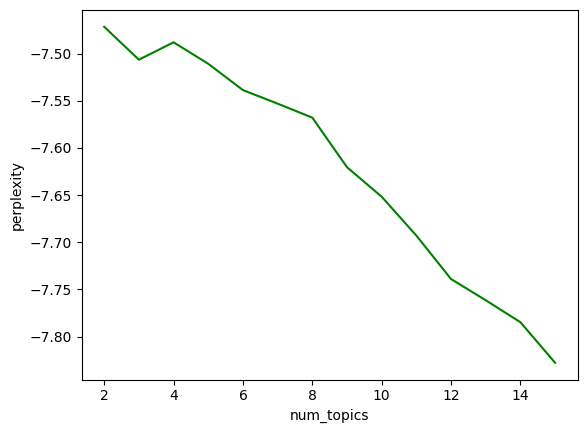

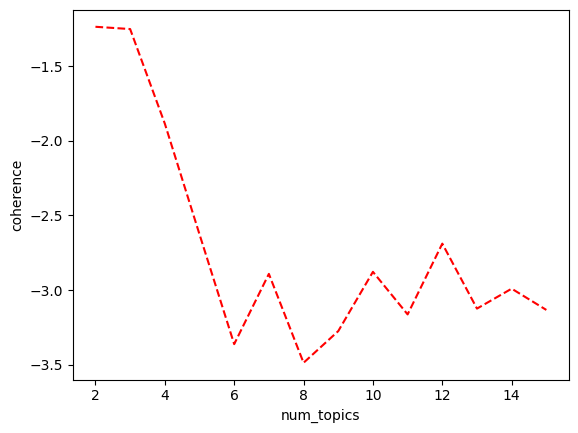

In [14]:
def show_coherence(corpus, dictionary, start=6, end=15):
    iter_num = []
    per_value = []
    coh_value = []

    for i in range(start, end + 1):
        model = LdaModel(corpus=corpus, id2word=dictionary,
                         chunksize=1000, num_topics=i,
                         random_state=7)
        iter_num.append(i)
        pv = model.log_perplexity(corpus)
        per_value.append(pv)

        cm = CoherenceModel(model=model, corpus=corpus,
                            coherence='u_mass')
        cv = cm.get_coherence()
        coh_value.append(cv)
        print(f'num_topics: {i}, perplexity: {pv:0.3f}, coherence: {cv:0.3f}')

    plt.plot(iter_num, per_value, 'g-')
    plt.xlabel("num_topics")
    plt.ylabel("perplexity")
    plt.show()

    plt.plot(iter_num, coh_value, 'r--')
    plt.xlabel("num_topics")
    plt.ylabel("coherence")
    plt.show()

show_coherence(corpus, dictionary, start=2, end=15)

In [15]:
from gensim.matutils import corpus2dense

pet_topics = corpus2dense(model.get_document_topics(corpus, minimum_probability=0),
                          num_terms=num_topics).T

trend_data = pd.DataFrame(pet_topics, columns=['Topic'+str(i) for i in range(1, num_topics + 1)])
trend_data = pd.concat([trend_data, ko['group'].reset_index(drop=True)], axis=1)
trend_data.iloc[:5, -5:]

,Topic4,Topic5,Topic6,Topic7,group
0,0.000486,0.997085,0.000486,0.000486,bts
1,0.995225,0.000797,0.000798,0.000795,bts
2,0.066250,0.572361,0.192379,0.000821,bts
3,0.001433,0.991401,0.001436,0.001433,bts
4,0.001393,0.001393,0.001393,0.991642,bts


In [16]:
trend = trend_data.groupby(['group']).mean()
trend

,Topic1,Topic2,Topic3,Topic4,Topic5,Topic6,Topic7
group,,,,,,,
bts,0.151592,0.095382,0.039552,0.140456,0.286898,0.212138,0.073982
베이비몬스터,0.426759,0.053775,0.094314,0.011048,0.006778,0.155446,0.251881
블랙핑크,0.300782,0.037187,0.057685,0.146395,0.073191,0.112729,0.272031
세븐틴,0.340495,0.084135,0.138832,0.071770,0.135342,0.143008,0.086418
코르티스,0.202014,0.057403,0.067343,0.064996,0.103391,0.482545,0.022308
트와이스,0.332310,0.078416,0.045761,0.100291,0.086706,0.188295,0.168222


In [17]:
ko['group'].value_counts()

group
bts       199
세븐틴       198
트와이스      197
블랙핑크      196
베이비몬스터    153
코르티스      143
Name: count, dtype: int64

In [18]:
ko.groupby('group')['published_at'].agg(['min', 'max'])

,min,max
group,,
bts,2017-01-23 14:03:27,2026-10-11 16:01:41
베이비몬스터,2023-07-11 12:24:46,2026-10-13 17:50:13
블랙핑크,2017-01-19 19:23:00,2026-10-09 11:56:06
세븐틴,2017-01-19 23:21:05,2026-10-10 14:47:13
코르티스,2025-08-11 11:11:00,2026-10-10 16:48:45
트와이스,2017-01-20 14:51:10,2026-10-12 16:58:16


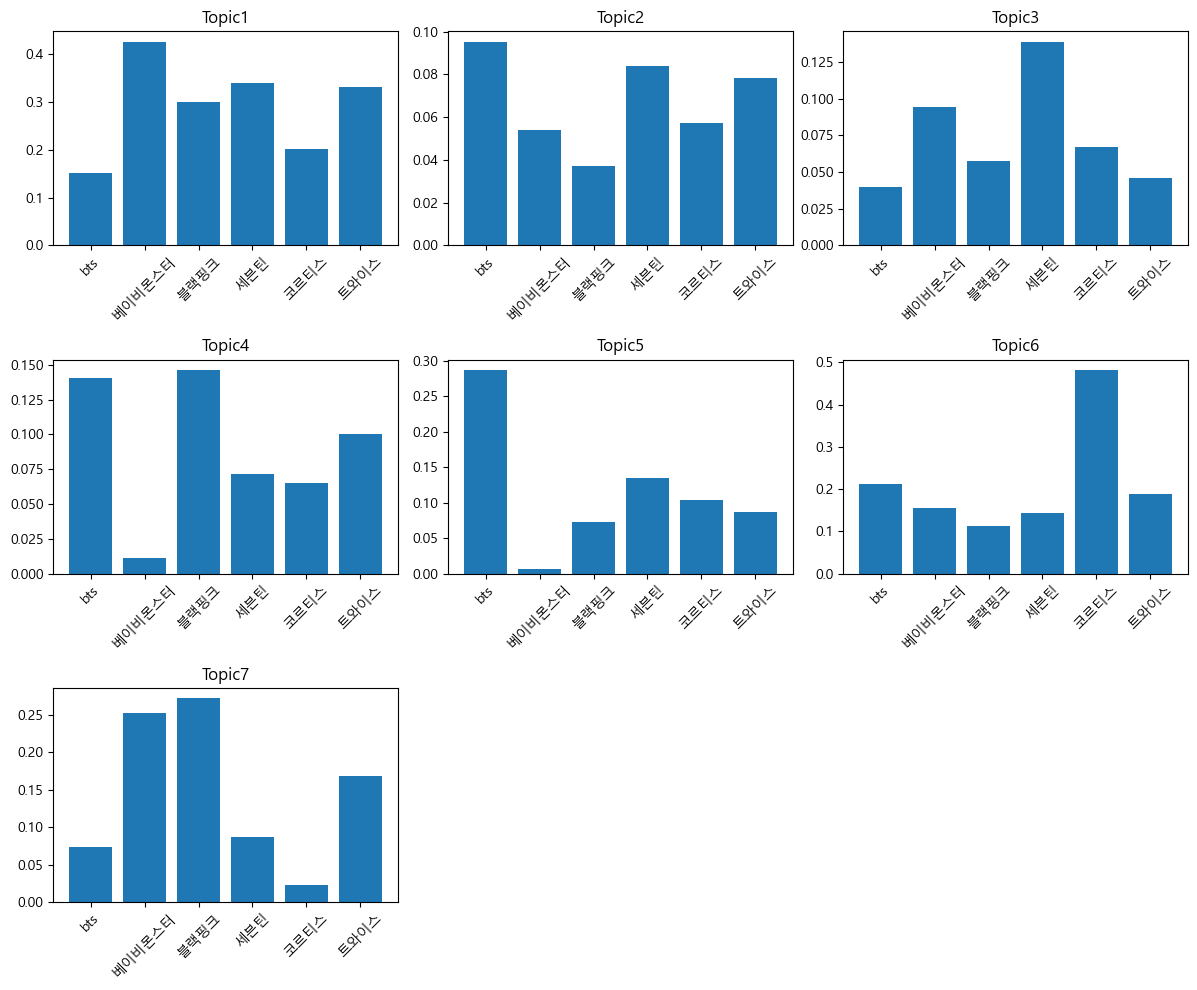

In [19]:
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
plt.rc('font', family='Malgun Gothic')

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for col, ax in zip(trend.columns.tolist(), axes.ravel()):
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
    ax.bar(trend.index, trend[col])
for ax in axes.ravel()[num_topics:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [20]:
model.print_topics(num_words=10)

[(0,
  '0.029*"일정" + 0.024*"인천국제공항" + 0.024*"오후" + 0.022*"중구" + 0.022*"출국" + 0.018*"해외" + 0.018*"입국" + 0.017*"가수" + 0.014*"참석" + 0.012*"패션"'),
 (1,
  '0.025*"일본" + 0.019*"무대" + 0.019*"공연" + 0.016*"팬" + 0.014*"콘서트" + 0.009*"데뷔" + 0.009*"투어" + 0.008*"관객" + 0.007*"현지" + 0.007*"음악"'),
 (2,
  '0.022*"서울" + 0.009*"로라" + 0.009*"오후" + 0.009*"아현" + 0.008*"파리타" + 0.008*"아사" + 0.007*"팬" + 0.007*"공개" + 0.007*"민규" + 0.007*"치키타"'),
 (3,
  '0.028*"브랜드" + 0.017*"지수" + 0.015*"분석" + 0.014*"그룹" + 0.014*"평판" + 0.012*"아티스트" + 0.007*"가수" + 0.006*"소속사" + 0.006*"팬" + 0.006*"공식"'),
 (4,
  '0.011*"앨범" + 0.011*"그룹" + 0.010*"무대" + 0.009*"음악" + 0.009*"미국" + 0.009*"차트" + 0.008*"공연" + 0.008*"팬" + 0.007*"빌보드" + 0.007*"발매"'),
 (5,
  '0.019*"곡" + 0.018*"앨범" + 0.017*"차트" + 0.011*"뮤직비디오" + 0.010*"데뷔" + 0.010*"공개" + 0.009*"그룹" + 0.008*"기록" + 0.008*"팬" + 0.008*"발매"'),
 (6,
  '0.018*"와이지엔터테인먼트" + 0.015*"공개" + 0.014*"팬" + 0.011*"제니" + 0.010*"공식" + 0.009*"그룹" + 0.007*"모습" + 0.007*"무대" + 0.007*"속" + 0.007*"매력"')]